
# Used Car Market Analysis
## Exploratory Data Analysis and Business Insights

### Objective
Analyze used-car listings across brands and cities to understand
pricing patterns, fuel preferences, transmission types, vehicle age,
and customer inventory trends.

### Dataset
Cleaned Cars24 used-car listing data.

### Tools
- Python
- Pandas and NumPy
- Matplotlib and Seaborn

### Analysis
- Univariate Analysis
- Bivariate Analysis
- Multivariate Analysis
- Business Questions
- Business Insights
- Business Recommendations


In [1]:

# Data analysis libraries
import pandas as pd
import numpy as np

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Display charts inside Google Colab
%matplotlib inline

# Set a consistent chart style
sns.set_theme(style="whitegrid")

print("EDA libraries imported successfully!")


EDA libraries imported successfully!


In [5]:

# Upload the cleaned CSV from your computer
from google.colab import files

uploaded = files.upload()

# Read the uploaded CSV file into a DataFrame
file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

# Preview the data
display(df.head())


Saving cleaned_used_cars.csv to cleaned_used_cars (1).csv
Dataset loaded successfully!
Dataset shape: (232, 17)


,Car_Name,Brand,City,Model_Year,Kilometers_Driven,Fuel_Type,Transmission,Price,Owner_Type,Location,URL,Needs_Review,Car_Age,KM_Category,Age_Category,Price_Category,Price_per_10k_KM
0,2020 Toyota Glanza V CVT,Toyota,Hyderabad,2020,86387,Petrol,Automatic,534000.0,NaN,"GVK One Mall, Banjara Hills, Hyderabad, Telangana",https://www.cars24.com/buy-used-toyota-cars-hy...,False,6.0,Medium,Moderate,Mid Range,61814.856402
1,2021 Toyota Glanza V,Toyota,Hyderabad,2021,105485,Petrol,Manual,551000.0,NaN,"Upperpally, Attapur, Hyderabad",https://www.cars24.com/buy-used-toyota-cars-hy...,False,5.0,High,Moderate,Mid Range,52234.914917
2,2021 Toyota Glanza G CVT,Toyota,Hyderabad,2021,70609,Petrol,Automatic,555000.0,NaN,"Bachupally, Hyderabad",https://www.cars24.com/buy-used-toyota-cars-hy...,False,5.0,Medium,Moderate,Mid Range,78601.877948
3,2025 Toyota Glanza V AMT,Toyota,Hyderabad,2025,19742,Petrol,Automatic,924000.0,NaN,"Kompally, Hyderabad",https://www.cars24.com/buy-used-toyota-cars-hy...,False,1.0,Low,New,Mid Range,468037.686151
4,2018 Toyota YARIS G CVT,Toyota,Hyderabad,2018,74307,Petrol,Automatic,531000.0,NaN,"Kompally, Hyderabad",https://www.cars24.com/buy-used-toyota-cars-hy...,False,8.0,Medium,Old,Mid Range,71460.293108


In [6]:

# Display the column names
print("Columns:")
print(df.columns.tolist())

# Check the data types and non-null counts
print("\nDataset information:")
df.info()

# Check missing values
print("\nMissing values by column:")
display(df.isnull().sum().to_frame("Missing_Count"))

# Check duplicate rows
print("\nExact duplicate rows:", df.duplicated().sum())

# Display basic numerical statistics
print("\nNumerical summary:")
display(df.describe())


Columns:
['Car_Name', 'Brand', 'City', 'Model_Year', 'Kilometers_Driven', 'Fuel_Type', 'Transmission', 'Price', 'Owner_Type', 'Location', 'URL', 'Needs_Review', 'Car_Age', 'KM_Category', 'Age_Category', 'Price_Category', 'Price_per_10k_KM']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 232 entries, 0 to 231
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Car_Name           232 non-null    object 
 1   Brand              232 non-null    object 
 2   City               232 non-null    object 
 3   Model_Year         232 non-null    int64  
 4   Kilometers_Driven  232 non-null    int64  
 5   Fuel_Type          232 non-null    object 
 6   Transmission       232 non-null    object 
 7   Price              232 non-null    float64
 8   Owner_Type         0 non-null      float64
 9   Location           232 non-null    object 
 10  URL                232 non-null    object 
 11  Nee

,Missing_Count
Car_Name,0
Brand,0
City,0
Model_Year,0
Kilometers_Driven,0
Fuel_Type,0
Transmission,0
Price,0
Owner_Type,232
Location,0



Exact duplicate rows: 0

Numerical summary:


,Model_Year,Kilometers_Driven,Price,Owner_Type,Car_Age,Price_per_10k_KM
count,232.000000,232.000000,2.320000e+02,0.0,232.000000,2.320000e+02
mean,2019.146552,65275.025862,6.702974e+05,NaN,6.853448,1.094575e+07
std,3.538910,34462.771031,3.611425e+05,NaN,3.538910,1.641220e+08
min,2011.000000,1.000000,1.420000e+05,NaN,0.000000,8.779066e+03
25%,2016.000000,39477.250000,4.422500e+05,NaN,4.000000,5.615445e+04
50%,2020.000000,61244.000000,5.950000e+05,NaN,6.000000,9.753682e+04
75%,2022.000000,89186.500000,7.935000e+05,NaN,10.000000,1.842570e+05
max,2026.000000,217563.000000,2.614000e+06,NaN,15.000000,2.500000e+09


In [7]:

# Convert important columns to numeric values
numeric_columns = [
    "Model_Year",
    "Kilometers_Driven",
    "Price",
    "Car_Age",
    "Price_per_10k_KM"
]

for column in numeric_columns:
    if column in df.columns:
        df[column] = pd.to_numeric(df[column], errors="coerce")

# Keep a separate DataFrame for price-based analysis
# Exclude missing or non-positive prices
df_analysis = df.loc[
    df["Price"].notna() & (df["Price"] > 0)
].copy()

print("Total cleaned records:", len(df))
print("Records with valid positive prices:", len(df_analysis))
print("Records excluded from price analysis:", len(df) - len(df_analysis))


Total cleaned records: 232
Records with valid positive prices: 232
Records excluded from price analysis: 0


# Univariate analysis

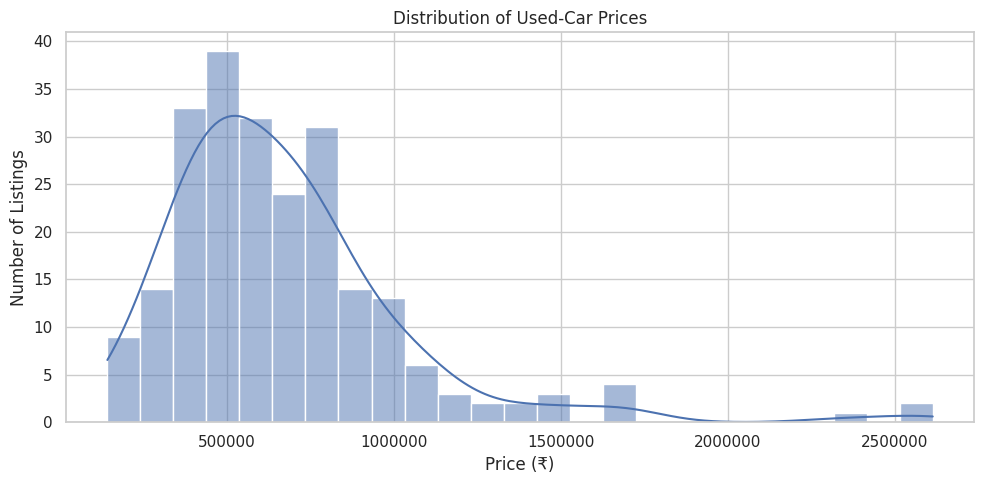

In [8]:

# Plot the distribution of used-car prices
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_analysis,
    x="Price",
    bins=25,
    kde=True
)

plt.title("Distribution of Used-Car Prices")
plt.xlabel("Price (₹)")
plt.ylabel("Number of Listings")
plt.ticklabel_format(style="plain", axis="x")

plt.tight_layout()
plt.savefig("01_price_distribution.png", dpi=300, bbox_inches="tight")
plt.show()


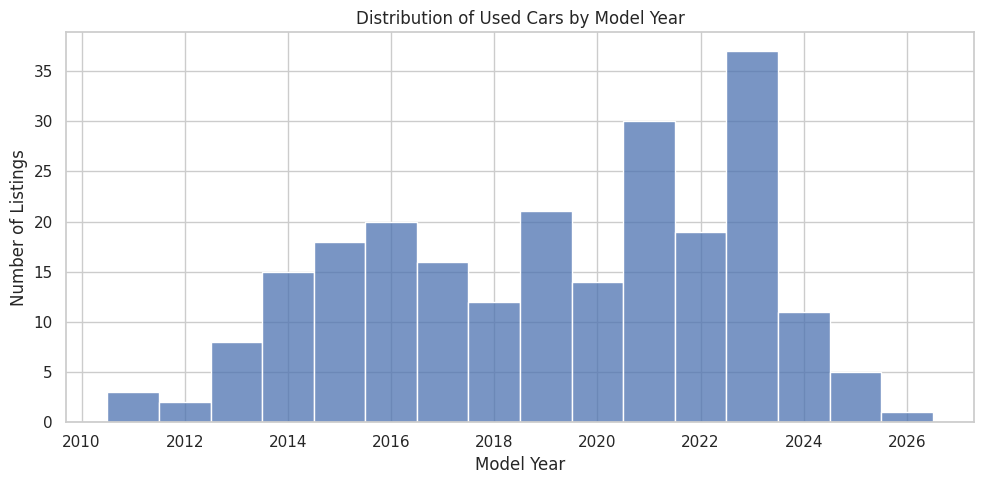

In [9]:

# Analyze the distribution of vehicle model years
year_data = df_analysis.dropna(subset=["Model_Year"]).copy()

plt.figure(figsize=(10, 5))

sns.histplot(
    data=year_data,
    x="Model_Year",
    bins=15,
    discrete=True
)

plt.title("Distribution of Used Cars by Model Year")
plt.xlabel("Model Year")
plt.ylabel("Number of Listings")

plt.tight_layout()
plt.savefig("02_model_year_distribution.png", dpi=300, bbox_inches="tight")
plt.show()


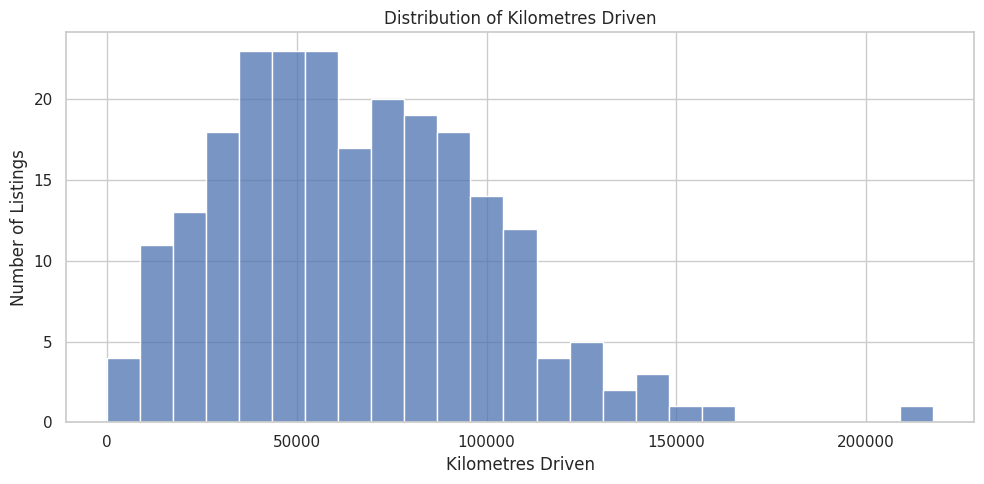

In [10]:

# Analyze how far the listed vehicles have been driven
km_data = df_analysis.dropna(subset=["Kilometers_Driven"])

plt.figure(figsize=(10, 5))

sns.histplot(
    data=km_data,
    x="Kilometers_Driven",
    bins=25
)

plt.title("Distribution of Kilometres Driven")
plt.xlabel("Kilometres Driven")
plt.ylabel("Number of Listings")

plt.tight_layout()
plt.savefig("03_kilometres_distribution.png", dpi=300, bbox_inches="tight")
plt.show()


# Bivariate analysis

Average price by city (₹):


,Average_Price
City,
Bangalore,725850.000000
Hyderabad,645150.000000
Chennai,636513.888889


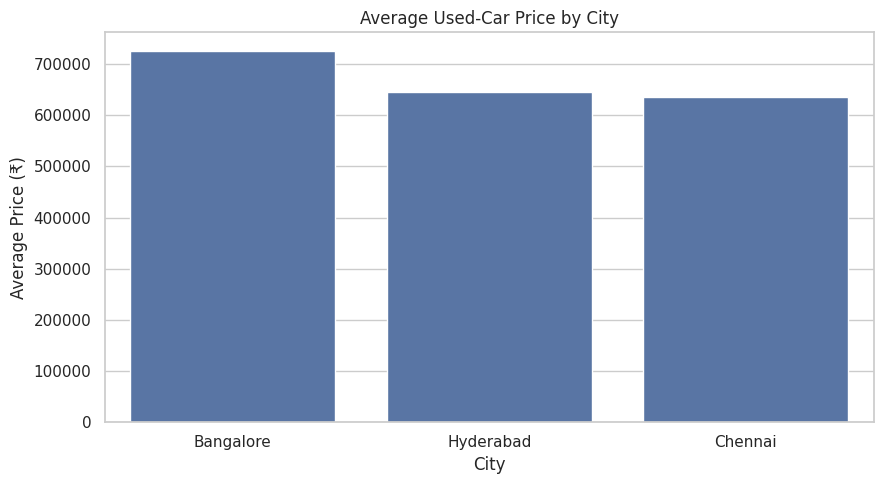

In [11]:

# Calculate the average price for each city
city_avg_price = (
    df_analysis.groupby("City")["Price"]
    .mean()
    .sort_values(ascending=False)
)

print("Average price by city (₹):")
display(city_avg_price.to_frame("Average_Price"))

# Visualize the results
plt.figure(figsize=(9, 5))

sns.barplot(
    x=city_avg_price.index,
    y=city_avg_price.values
)

plt.title("Average Used-Car Price by City")
plt.xlabel("City")
plt.ylabel("Average Price (₹)")
plt.ticklabel_format(style="plain", axis="y")

plt.tight_layout()
plt.savefig("04_average_price_by_city.png", dpi=300, bbox_inches="tight")
plt.show()


Average price by brand (₹):


,Average_Price
Brand,
Toyota,745903.846154
Tata,707316.666667
Hyundai,675333.333333
Honda,562716.666667


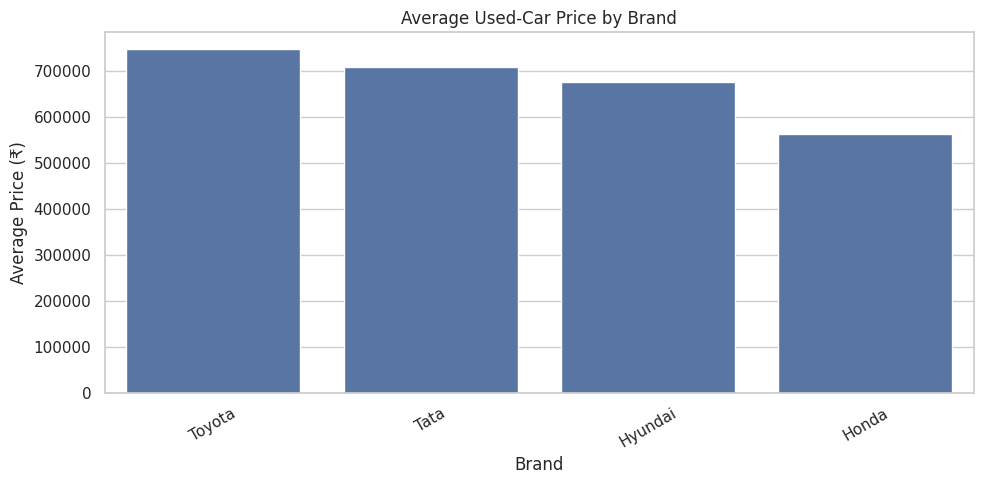

In [13]:

# Calculate the average price for each brand
brand_avg_price = (
    df_analysis.groupby("Brand")["Price"]
    .mean()
    .sort_values(ascending=False)
)

print("Average price by brand (₹):")
display(brand_avg_price.to_frame("Average_Price"))

# Create the bar chart
plt.figure(figsize=(10, 5))

sns.barplot(
    x=brand_avg_price.index,
    y=brand_avg_price.values
)

plt.title("Average Used-Car Price by Brand")
plt.xlabel("Brand")
plt.ylabel("Average Price (₹)")
plt.xticks(rotation=30)
plt.ticklabel_format(style="plain", axis="y")

plt.tight_layout()
plt.savefig("05_average_price_by_brand.png", dpi=300, bbox_inches="tight")
plt.show()


Price summary by fuel type:


,count,mean,median
Fuel_Type,,,
Hybrid,4,1.599750e+06,1316000.0
Diesel,31,8.620323e+05,795000.0
Cng,3,7.620000e+05,800000.0
Petrol,194,6.190773e+05,581500.0


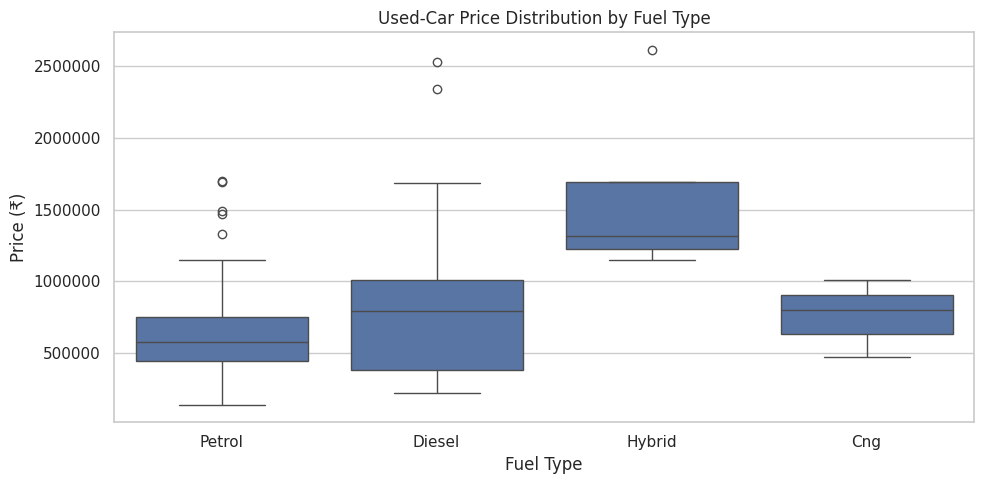

In [14]:

# Summarize average price and listing count by fuel type
fuel_summary = (
    df_analysis.groupby("Fuel_Type", observed=True)["Price"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)

print("Price summary by fuel type:")
display(fuel_summary)

# Compare the price distributions
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df_analysis,
    x="Fuel_Type",
    y="Price"
)

plt.title("Used-Car Price Distribution by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Price (₹)")
plt.ticklabel_format(style="plain", axis="y")

plt.tight_layout()
plt.savefig("06_price_by_fuel_type.png", dpi=300, bbox_inches="tight")
plt.show()


Price summary by transmission:


,count,mean,median
Transmission,,,
Automatic,86,840093.023256,744000.0
Manual,146,570280.821918,518500.0


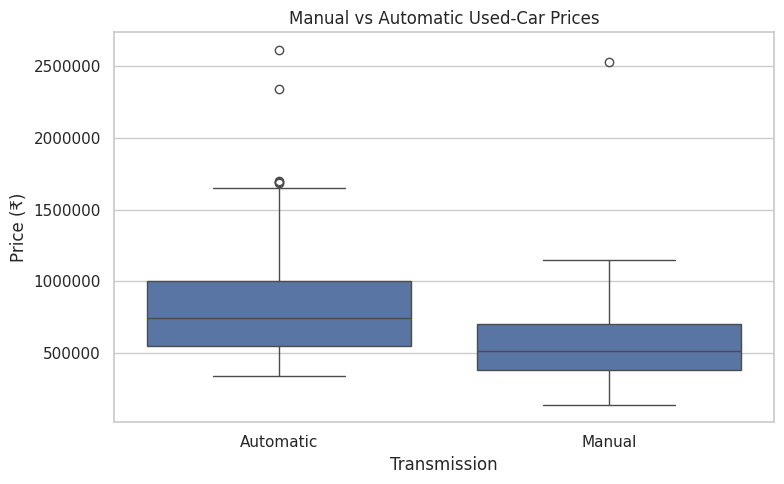

In [15]:

# Calculate summary statistics for each transmission type
transmission_summary = (
    df_analysis.groupby("Transmission", observed=True)["Price"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)

print("Price summary by transmission:")
display(transmission_summary)

# Visualize the price distributions
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_analysis[
        df_analysis["Transmission"].isin(["Manual", "Automatic"])
    ],
    x="Transmission",
    y="Price"
)

plt.title("Manual vs Automatic Used-Car Prices")
plt.xlabel("Transmission")
plt.ylabel("Price (₹)")
plt.ticklabel_format(style="plain", axis="y")

plt.tight_layout()
plt.savefig("07_price_by_transmission.png", dpi=300, bbox_inches="tight")
plt.show()


# Multivariate analysis

Average price by brand and city:


City,Bangalore,Chennai,Hyderabad
Brand,,,
Honda,590300.0,596450.000000,501400.0
Hyundai,726950.0,664150.000000,634900.0
Tata,777250.0,577450.000000,767250.0
Toyota,808900.0,755666.666667,677050.0


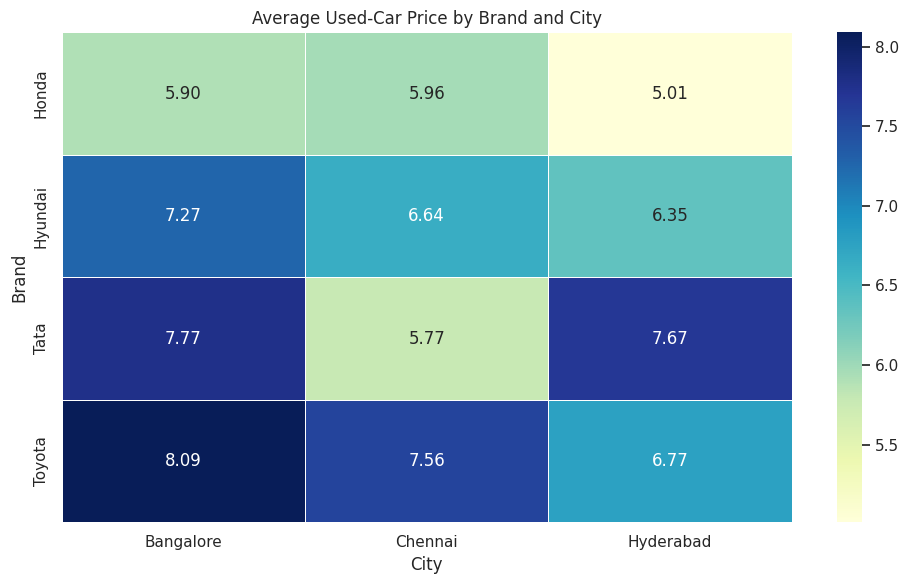

In [16]:

# Create a matrix of average prices for each brand-city combination
price_pivot = pd.pivot_table(
    df_analysis,
    values="Price",
    index="Brand",
    columns="City",
    aggfunc="mean",
    observed=True
)

print("Average price by brand and city:")
display(price_pivot)

# Plot the heatmap
plt.figure(figsize=(10, 6))

sns.heatmap(
    price_pivot / 100000,  # Convert rupees to lakh for readability
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Average Used-Car Price by Brand and City")
plt.xlabel("City")
plt.ylabel("Brand")
plt.tight_layout()

plt.savefig("08_brand_city_price_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()


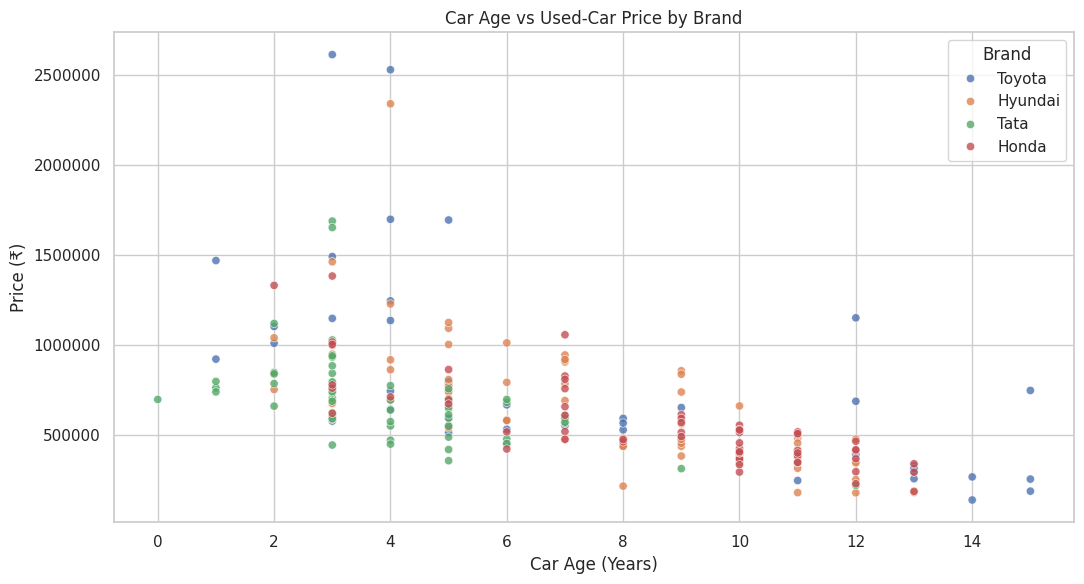

In [17]:

# Keep records with valid age and price
age_price_data = df_analysis.dropna(
    subset=["Car_Age", "Price", "Brand"]
).copy()

plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=age_price_data,
    x="Car_Age",
    y="Price",
    hue="Brand",
    alpha=0.8
)

plt.title("Car Age vs Used-Car Price by Brand")
plt.xlabel("Car Age (Years)")
plt.ylabel("Price (₹)")
plt.ticklabel_format(style="plain", axis="y")

plt.tight_layout()
plt.savefig("09_car_age_vs_price.png", dpi=300, bbox_inches="tight")
plt.show()


Correlation between kilometres and price: -0.233


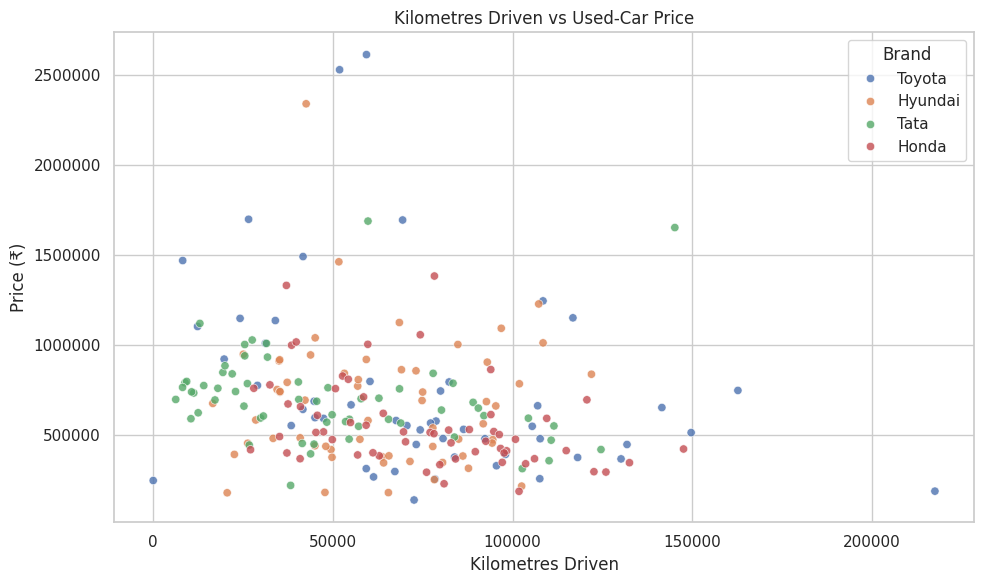

In [18]:

# Keep records with valid kilometres and prices
km_price_data = df_analysis.dropna(
    subset=["Kilometers_Driven", "Price"]
).copy()

# Calculate the Pearson correlation
correlation = km_price_data[
    ["Kilometers_Driven", "Price"]
].corr().iloc[0, 1]

print(f"Correlation between kilometres and price: {correlation:.3f}")

# Plot the relationship
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=km_price_data,
    x="Kilometers_Driven",
    y="Price",
    hue="Brand",
    alpha=0.8
)

plt.title("Kilometres Driven vs Used-Car Price")
plt.xlabel("Kilometres Driven")
plt.ylabel("Price (₹)")
plt.ticklabel_format(style="plain", axis="y")

plt.tight_layout()
plt.savefig("10_kilometres_vs_price.png", dpi=300, bbox_inches="tight")
plt.show()


In [23]:

# Q1: City with the highest average price
q1 = df_analysis.groupby("City")["Price"].mean().idxmax()

# Q2: Brand with the highest average price
q2 = df_analysis.groupby("Brand")["Price"].mean().idxmax()

# Q3: Brand with the most listings
q3 = df_analysis["Brand"].value_counts().idxmax()

# Q4: Fuel type with the highest average price
q4 = df_analysis.groupby("Fuel_Type")["Price"].mean().idxmax()

# Q5: Average price by transmission
q5 = df_analysis.groupby("Transmission")["Price"].mean().round(2).to_dict()

# Q6: Average price by car-age category
q6 = df_analysis.groupby("Age_Category", observed=True)["Price"].mean().round(2).to_dict()

# Q7: Correlation between kilometres and price
q7 = df_analysis[["Kilometers_Driven", "Price"]].corr().iloc[0, 1]

# Q8: Brand with the highest average kilometres driven
q8 = df_analysis.groupby("Brand")["Kilometers_Driven"].mean().idxmax()

# Q9: City with the most listings
q9 = df_analysis["City"].value_counts().idxmax()

# Q10: Brand-city combination with the highest average price
q10 = (
    df_analysis.groupby(["Brand", "City"])["Price"]
    .mean()
    .idxmax()
)

# Display the answers
business_answers = pd.DataFrame({
    "Business_Question": [
        "Which city has the highest average price?",
        "Which brand has the highest average price?",
        "Which brand has the most listings?",
        "Which fuel type has the highest average price?",
        "What is the average price by transmission?",
        "What is the average price by age category?",
        "What is the correlation between kilometres and price?",
        "Which brand has the highest average kilometres driven?",
        "Which city has the most listings?",
        "Which brand-city combination has the highest average price?"
    ],
    "Answer": [
        q1,
        q2,
        q3,
        q4,
        str(q5),
        str(q6),
        round(q7, 3),
        q8,
        q9,
        str(q10)
    ]
})

display(business_answers)


,Business_Question,Answer
0,Which city has the highest average price?,Bangalore
1,Which brand has the highest average price?,Toyota
2,Which brand has the most listings?,Hyundai
3,Which fuel type has the highest average price?,Hybrid
4,What is the average price by transmission?,"{'Automatic': 840093.02, 'Manual': 570280.82}"
5,What is the average price by age category?,"{'Moderate': 782476.19, 'New': 942870.37, 'Old..."
6,What is the correlation between kilometres and...,-0.233
7,Which brand has the highest average kilometres...,Toyota
8,Which city has the most listings?,Hyderabad
9,Which brand-city combination has the highest a...,"('Toyota', 'Bangalore')"


In [20]:

# Identify the highest-priced city and brand by average price
city_means = df_analysis.groupby("City")["Price"].mean()
brand_means = df_analysis.groupby("Brand")["Price"].mean()

# Calculate listing shares
brand_counts = df_analysis["Brand"].value_counts()
city_counts = df_analysis["City"].value_counts()

# Calculate the correlation between kilometres and price
km_price_corr = df_analysis[
    ["Kilometers_Driven", "Price"]
].corr().iloc[0, 1]

insights = [
    (
        f"{city_means.idxmax()} has the highest average listing price "
        f"among the cities in the collected sample "
        f"(₹{city_means.max():,.0f})."
    ),
    (
        f"{brand_means.idxmax()} has the highest average listing price "
        f"among the four selected brands "
        f"(₹{brand_means.max():,.0f})."
    ),
    (
        f"{brand_counts.idxmax()} has the largest number of listings "
        f"in the collected sample ({brand_counts.max()} listings)."
    ),
    (
        f"{city_counts.idxmax()} has the largest number of collected "
        f"listings ({city_counts.max()} listings)."
    ),
    (
        f"The Pearson correlation between kilometres driven and price "
        f"is {km_price_corr:.3f}."
    )
]

print("Initial data-driven insights:\n")

for number, insight in enumerate(insights, start=1):
    print(f"{number}. {insight}")


Initial data-driven insights:

1. Bangalore has the highest average listing price among the cities in the collected sample (₹725,850).
2. Toyota has the highest average listing price among the four selected brands (₹745,904).
3. Hyundai has the largest number of listings in the collected sample (60 listings).
4. Hyderabad has the largest number of collected listings (80 listings).
5. The Pearson correlation between kilometres driven and price is -0.233.


In [21]:

recommendations = [
    "Use city-specific price benchmarks rather than assuming one national price level.",
    "Compare brand-level prices after accounting for vehicle age and kilometres driven.",
    "Review automatic and manual inventory separately if their price distributions differ.",
    "Use vehicle age and kilometres driven as inputs when developing pricing bands.",
    "Collect additional pages and valid Delhi listings before making market-wide conclusions."
]

print("Business recommendations:\n")

for number, recommendation in enumerate(recommendations, start=1):
    print(f"{number}. {recommendation}")


Business recommendations:

1. Use city-specific price benchmarks rather than assuming one national price level.
2. Compare brand-level prices after accounting for vehicle age and kilometres driven.
3. Review automatic and manual inventory separately if their price distributions differ.
4. Use vehicle age and kilometres driven as inputs when developing pricing bands.
5. Collect additional pages and valid Delhi listings before making market-wide conclusions.
